In [1]:
import xarray as xr
from pathlib import Path
import pandas as pd
import rioxarray as rxr
import numpy as np
import matplotlib.pyplot as plt
import warnings
from scipy import stats
from sklearn.decomposition import PCA


In [4]:
folder = Path(r"P:\archivedprojects\11211461-010--eo-flood-ops\HoiAn\classified_events")
files = sorted(folder.glob("hoian_*.tif"))

if not files:
    raise FileNotFoundError(f"No TIFF files found in {folder}")

floodmaps = []
for file in files:
    timestamp = pd.to_datetime(
    file.stem.replace("hoian_", "", 1),
    format="%Y%m%dT%H%M%S",
    )

    floodmap = rxr.open_rasterio(file, chunks="auto").squeeze(
        "band", drop=True
    )
    floodmaps.append(floodmap.expand_dims(time=[timestamp]))

ds = xr.concat(floodmaps, dim="time").sortby("time").to_dataset(
    name="floodmap"
)


### Ortho rotation function

In [3]:
def _ortho_rotation(
    components, 
    method="varimax", 
    tol=1e-6, 
    max_iter=100
):
    """Return orthogonally rotated component loadings."""
    nrow, ncol = components.shape
    rotation_matrix = np.eye(ncol)
    variance = 0

    for _ in range(max_iter):
        components_rotated = np.dot(components, rotation_matrix)
        if method == "varimax":
            correction = components_rotated * np.transpose(
                (components_rotated**2).sum(axis=0) / nrow
            )
        else:
            correction = 0

        u, singular_values, vh = np.linalg.svd(
            np.dot(components.T, components_rotated**3 - correction),
            full_matrices=False,
        )
        rotation_matrix = np.dot(u, vh)
        variance_new = np.sum(singular_values)
        if variance != 0 and variance_new < variance * (1 + tol):
            break
        variance = variance_new

    return np.dot(components, rotation_matrix)

### Significant test

In [8]:
def _sig_eof_test(
    da: xr.DataArray,
    option: str = "monte_carlo",
    monte_carlo_iter: int = 5,
    time_dim: str = "time",
    y_dim: str = "lat",
    x_dim: str = "lon",
):
    """
    Determine the number of significant EOF modes to retain for rotation.

    args:
        da (xr.DataArray): Input DataArray containing satellite imagery
        option (str): Significant test to use: "monte_carlo" or "north"
        monte_carlo_iter (int): Iteration time for the Monte Carlo test
        time_dim (str): Name of the time dimension. default = "time"
        y_dim (str): Name of the latitude/y dimension. default = "lat"
        x_dim (str): Name of the longitude/x dimension. default = "lon"

    output:
        sig_mode (int): Number of modes to retain for the rotation of EOF analysis results
    """
    if option not in ["monte_carlo", "north"]:
        raise ValueError("option must be 'monte_carlo' or 'north'")

    if monte_carlo_iter < 1:
        raise ValueError("monte_carlo_iter must be at least one")

    time_size = da.sizes[time_dim]
    y_size = da.sizes[y_dim]
    x_size = da.sizes[x_dim]
    space_size = y_size * x_size

    flat_da = da.values.reshape((time_size, space_size))
    aoi_mask_flat = ~(np.isnan(flat_da).all(axis=0))
    flat_da = flat_da[:, aoi_mask_flat]
    flat_da = flat_da - flat_da.mean(axis=0, keepdims=True)

    if flat_da.shape[1] == 0:
        raise ValueError("The input DataArray contains no valid spatial pixels")

    # ----- sklearn PCA (eigenvalues of real data) -----
    pca = PCA(n_components=time_size)
    pca.fit_transform(flat_da)
    real_lamb = pca.explained_variance_

    if option == "monte_carlo":
        mc_lamb = np.full((time_size, monte_carlo_iter), np.nan)
        rng = np.random.default_rng()

        # ----- Monte Carlo simulation -----
        for i in range(monte_carlo_iter):
            # ----- Randomize observations by spatially shuffling the data -----
            obs_temp = rng.permuted(flat_da, axis=1)

            pca = PCA(n_components=time_size)
            pca.fit_transform(obs_temp)
            mc_lamb[:, i] = pca.explained_variance_

        mc_lamb = np.transpose(mc_lamb)
        mean_mc_lamb = np.mean(mc_lamb, axis=0)
        sig_bool = real_lamb > mean_mc_lamb

        sig_mode = time_size
        for i in range(time_size):
            if not sig_bool[i]:
                sig_mode = i
                break

    else:
        lamb_err = real_lamb * np.sqrt(2 / time_size)
        lower_lamb = real_lamb - lamb_err
        upper_lamb = real_lamb + lamb_err

        sig_bool = lower_lamb[:-1] > upper_lamb[1:]

        sig_mode = time_size
        for i in range(len(sig_bool)):
            if not sig_bool[i]:
                sig_mode = i
                break

    return sig_mode

In [13]:
def reof(
    da: xr.DataArray,
    n_modes: int = 4,
    significance_test: bool = False,
    time_dim: str = "time",
    y_dim: str = "lat",
    x_dim: str = "lon",
    method: str = "varimax",
    tol: float = 1e-6,
    max_iter: int = 100,
) -> xr.Dataset:
    """
    Perform Rotated Empirical Orthogonal Function (REOF) on multi-temporal satellite images

    args:
        da (xr.DataArray): DataArray of spatial temporal values with dims (time_dim, y_dim, x_dim)
        n_modes (int): number of eof modes to use when significance_test is False. default = 4
        significance_test (bool): if True, determine n_modes using a significance test. default = False
        time_dim (str): name of the time dimension/coordinate. default = "time"
        y_dim (str): name of the latitude/y dimension/coordinate. default = "lat"
        x_dim (str): name of the longitude/x dimension/coordinate. default = "lon"
        method (str): rotation method passed to `_ortho_rotation`, "varimax" or "quartimax". default = "varimax"
        tol (float): convergence tolerance passed to `_ortho_rotation`. default = 1e-6
        max_iter (int): maximum number of rotation iterations passed to `_ortho_rotation`. default = 100

    returns:
        reof_ds (xr.Dataset): Dataset of REOF results with spatial modes, temporal modes, mean of data, and
        explained variances as variables
    """
    if method not in ["varimax", "quartimax"]:
        raise ValueError("method must be 'varimax' or 'quartimax'")
    if not np.isscalar(tol) or not np.isfinite(tol) or tol <= 0:
        raise ValueError("tol must be a finite value greater than zero")
    if not isinstance(max_iter, (int, np.integer)) or isinstance(max_iter, bool):
        raise TypeError("max_iter must be an integer")
    if max_iter < 1:
        raise ValueError("max_iter must be at least one")
    if not isinstance(significance_test, (bool, np.bool_)):
        raise TypeError("significance_test must be a boolean")

    time_size = da.sizes[time_dim]
    y_size = da.sizes[y_dim]
    x_size = da.sizes[x_dim]
    space_size = y_size * x_size

    if significance_test:
        print("Performing significance test to determine the number of EOF modes...")
        n_modes = _sig_eof_test(
            da=da,
            time_dim=time_dim,
            y_dim=y_dim,
            x_dim=x_dim,
        )
        print(f"Number of EOF modes determined by significance test: {n_modes}")

    print(f"Performing REOF analysis using the first {n_modes} modes...")

    temporal_mean = np.nanmean(da.values, axis=0)

    flat_da = da.values.reshape((time_size, space_size))
    aoi_mask_flat = ~(np.isnan(flat_da).all(axis=0))
    flat_da = flat_da[:, aoi_mask_flat]
    flat_da = flat_da - flat_da.mean(axis=0, keepdims=True)

    # Record the original index of each pixels inside the AOI
    # to recover the flattened data back to geographical dimension
    flat2geo = np.arange(np.prod(space_size))[aoi_mask_flat].reshape(1, -1)

    # sklearn PCA
    pca = PCA(n_components=n_modes)
    pca.fit_transform(flat_da)
    expvar = pca.explained_variance_ratio_
    eofs = (pca.components_).T

    rotated_eofs = _ortho_rotation(
        eofs, method=method, 
        tol=tol, 
        max_iter=max_iter
    )

    # project the original time series data on the rotated eofs
    rotated_pcs = np.dot(flat_da, rotated_eofs)

    # get variance of each rotated mode
    rotated_var = np.var(rotated_pcs, axis=0)

    # get cumulative variance of all rotated modes
    total_rotated_var = rotated_var.cumsum()[-1]

    # get variance fraction of each rotated mode
    rotated_var_frac = (rotated_var / total_rotated_var) * np.sum(expvar)

    # recover the flattened, AOI-only EOF array back to the geographical dimension
    rotated_eofs = rotated_eofs.T
    rotated_pcs = rotated_pcs.T

    # index of explained variance in the descending order
    sort_rotated_var_frac = np.argsort(-1 * rotated_var_frac)  
    rotated_var_frac = rotated_var_frac[sort_rotated_var_frac]

    # sort modes based on variance fraction of REOF
    indx_rotated_var_frac_sort = np.expand_dims(sort_rotated_var_frac, axis=-1)  # Mode X 1
    rotated_pcs = np.take_along_axis(rotated_pcs, indx_rotated_var_frac_sort, axis=0)

    rotated_eofs = np.take_along_axis(rotated_eofs, indx_rotated_var_frac_sort, axis=0)
    fill_eofs = np.ones((n_modes, space_size)) * np.nan
    for ct_c in np.arange(rotated_eofs.shape[1]):
        fill_eofs[:, flat2geo[0, ct_c]] = rotated_eofs[:, ct_c]
    rec_eofs_img = fill_eofs.reshape(n_modes, y_size, x_size)

    # define data with variable attributes
    data_vars = {
        "spatial_modes": (["mode", y_dim, x_dim], rec_eofs_img),
        "temporal_modes": (["mode", time_dim], rotated_pcs),
        "temporal_mean": ([y_dim, x_dim], temporal_mean),
        "explained_var": (["mode"], rotated_var_frac),
    }

    # define coordinates
    coords = {
        time_dim: ([time_dim], da[time_dim].values),
        y_dim: ([y_dim], da[y_dim].values, {"units": "degrees North"}),
        x_dim: ([x_dim], da[x_dim].values, {"units": "degrees East"}),
        "mode": (["mode"], np.arange(n_modes) + 1),
    }

    # create dataset
    reof_ds = xr.Dataset(
        data_vars=data_vars,
        coords=coords,
    )

    return reof_ds

In [14]:
eof_result = reof(
    da=ds["floodmap"],
    significance_test=True,
    y_dim= "y",
    x_dim= "x",
)

Performing significance test to determine the number of EOF modes...
Number of EOF modes determined by significance test: 3
Performing REOF analysis using the first 3 modes...


In [15]:
eof_result

<xarray.Dataset> Size: 885MB
Dimensions:         (mode: 3, y: 4879, x: 5668, time: 4)
Coordinates:
  * mode            (mode) int64 24B 1 2 3
  * y               (y) float64 39kB 16.22 16.22 16.22 16.22 ... 14.9 14.9 14.9
  * x               (x) float64 45kB 107.2 107.2 107.2 ... 108.7 108.7 108.7
  * time            (time) datetime64[ns] 32B 2022-10-15T10:56:00 ... 2023-11...
Data variables:
    spatial_modes   (mode, y, x) float64 664MB -3.682e-13 -7.288e-16 ... 0.0 0.0
    temporal_modes  (mode, time) float64 96B 166.1 -191.8 ... -215.1 0.964
    temporal_mean   (y, x) float64 221MB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    explained_var   (mode) float64 24B 0.421 0.3087 0.2703

In [16]:
waterlevels_fn = R"p:\archivedprojects\11211461-010--eo-flood-ops\HoiAn\water_levels\Water_Level.csv"

df_water = pd.read_csv(waterlevels_fn, skiprows=[1])
df_water.rename(columns={df_water.columns[0]: "datetime"}, inplace=True)
df_water["datetime"] = pd.to_datetime(df_water["datetime"])

# convert timezone from GMT+7 to UTC
df_water["datetime"] = df_water["datetime"] - pd.Timedelta(hours=7)

# set index to datetime
df_water.set_index("datetime", inplace=True)
df_water.replace(-999, np.nan, inplace=True)

da_water = xr.DataArray(
    df_water.to_numpy(),
    coords={
        "time": ("time", df_water.index.to_numpy()),
        "site": ("site", df_water.columns.to_numpy()),
    },
    dims=("time", "site"),
    name="water_level",
)

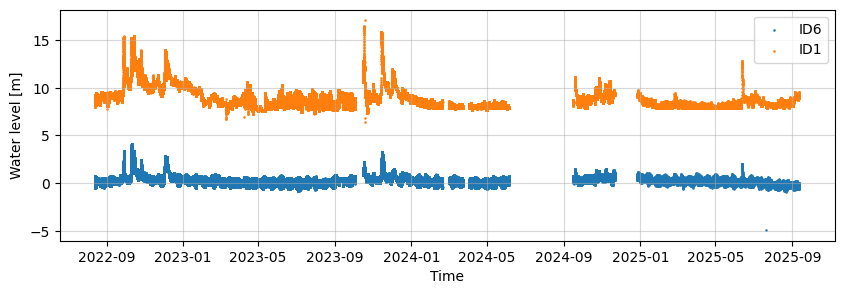

In [46]:
fig, ax = plt.subplots(figsize=(10, 3))

# Plot water level for site ID6 as points
ax.scatter(da_water.sel(site="ID6").time, da_water.sel(site="ID6").values, label="ID6", s=0.7)
ax.scatter(da_water.sel(site="ID6").time, da_water.sel(site="ID1").values, label="ID1", s=0.7)

ax.set_xlabel("Time")
ax.set_ylabel("Water level [m]")
ax.legend()
ax.grid(True, alpha=0.5)

In [ ]:
def find_closest_valid_hydro(
    da_hydro: xr.DataArray,
    times: np.ndarray,
    time_dim: str = "time",
    site_dim: str = "site",
    warn_thrd: pd.Timedelta = pd.Timedelta(hours=5),
    error_thrd: pd.Timedelta = pd.Timedelta(days=1),
    verbose: bool = False,
) -> xr.DataArray:
    """
    For each requested timestamp, find the closest valid (non-NaN) hydrological
    observation per site.

    args:
        da_hydro: DataArray with hydrological data, with dims (site_dim, time_dim)
        times: requested timestamps (e.g. satellite acquisition times) to match against
        time_dim: name of the time dimension/coordinate. default = "time"
        site_dim: name of the site/gauge dimension/coordinate. default = "site"
        warn_thrd: warn if the closest valid observation is farther than this. default = 5 hours
        error_thrd: raise if the closest valid observation is farther than this. default = 1 day
        verbose: if True, print site, image time and matched observation time for each match. default = False

    returns:
        xr.DataArray with dims (site_dim, time_dim) aligned to `times`, holding the
        closest valid observation per site
    """
    query_times = np.asarray(times, dtype="datetime64[ns]")
    sites = da_hydro[site_dim].values

    matched = np.full((len(sites), len(query_times)), np.nan)

    for si, site in enumerate(sites):
        valid = da_hydro.sel({site_dim: site}).dropna(time_dim)
        valid_times = valid[time_dim].values
        if valid_times.size == 0:
            continue

        if valid_times.size == 1:
            nearest_idx = np.zeros(len(query_times), dtype=int)
        else:
            idx = np.clip(np.searchsorted(valid_times, query_times), 1, valid_times.size - 1)
            left_diff = np.abs(query_times - valid_times[idx - 1])
            right_diff = np.abs(valid_times[idx] - query_times)
            nearest_idx = np.where(right_diff < left_diff, idx, idx - 1)

        gaps = pd.to_timedelta(np.abs(query_times - valid_times[nearest_idx]))
        for ti, gap in enumerate(gaps):
            if verbose:
                print(
                    f"site={site}  image_time={query_times[ti]}  "
                    f"closest_obs_time={valid_times[nearest_idx[ti]]}  gap={gap}"
                )
            if gap > error_thrd:
                raise ValueError(
                    f"Closest valid obs for {site} is {gap} away "
                    f"(at {valid_times[nearest_idx[ti]]}). Requested timestamp: {query_times[ti]}"
                )
            if gap > warn_thrd:
                warnings.warn(
                    f"Closest valid obs for {site} is {gap} away "
                    f"(at {valid_times[nearest_idx[ti]]}). Requested timestamp: {query_times[ti]}"
                )
        matched[si] = valid.values[nearest_idx]

    return xr.DataArray(
        matched,
        dims=(site_dim, time_dim),
        coords={site_dim: sites, time_dim: query_times},
    )


def find_hydro_mode(
    ds_eof: xr.Dataset,
    da_hydro: xr.DataArray,
    r_thrd: float = 0.5,
    p_thrd: float = 0.05,
    time_dim: str = "time",
    site_dim: str = "site",
) -> xr.Dataset:
    """
    Calculate correlation between temporal patterns and hydrological data.
    This helps determine water-related mode. By default,  >=0.5 is considered to be correlated.

    args:
       ds_eof: Dataset with REOF results produced by the `reof()` function
       da_hydro: DataArray with hydrological data
       r_thrd: Threshold (default: 0.5) of correlation coefficient to decide which modes are water-related
       p_thrd: Threshold (default: 0.05) of p-value below which a correlation is considered significant
       time_dim: name of the time dimension/coordinate shared between ds_eof and da_hydro. default = "time"
       site_dim: name of the site/gauge dimension/coordinate in da_hydro. default = "site"

    output (site X modes):
       site: Names of selected sites of the modes
       best_r: The highest correlations between RTPCs and hydrological data
       best_p: Corresponding p-values of best_r
    """
    # "mode" is always the dim name produced by reof(), 
    # so it is not parameterized here
    mode_dim = "mode"

    # get number of mode
    mode_num = ds_eof.sizes[mode_dim]
    # get number of hydrological data sites
    site_num = da_hydro.sizes[site_dim]

    r = np.zeros((site_num, mode_num))
    p = np.zeros((site_num, mode_num))

    time_tpc = ds_eof.temporal_modes.sel({mode_dim: int(1)})[time_dim]
    # hydro measurements rarely land on the exact satellite acquisition timestamps,
    # so match each satellite timestamp to the closest valid hydro observation instead
    hydro_common = find_closest_valid_hydro(da_hydro, time_tpc.values, time_dim=time_dim, site_dim=site_dim)
    hydro_site = hydro_common[site_dim].values
    hydro_values = hydro_common.values

    n = hydro_values.shape[-1]
    p_dist = stats.beta(n/2 - 1, n/2 - 1, loc=-1, scale=2)

    # ----- Instead of using FOR, see if it is possible to vectorize the process -----
    for ct_mode in range(mode_num):
        # get mode of tpc
        tpc = ds_eof.temporal_modes.sel({mode_dim: int(ct_mode+1)})
        tpc = tpc.expand_dims(dim=site_dim, axis=0).values.reshape(1,-1)

        r_da = np.concatenate((tpc, hydro_values), axis=0)
        r_mode = np.expand_dims((pd.DataFrame(np.transpose(r_da)).corr(method='pearson').values[1:,0]), axis=1)
        p_mode = 2*p_dist.cdf(-abs(r_mode))

        if ct_mode==0:
            r = r_mode
            p = p_mode
        else:
            r = np.concatenate((r,r_mode), axis=1)
            p = np.concatenate((p,p_mode), axis=1)

    indx_max_r_site = np.nanargmax(np.abs(r), axis=0)
    r_temp = r[( indx_max_r_site, list(range(mode_num)) )]
    p_temp = p[( indx_max_r_site, list(range(mode_num)) )]

    mode_out = ((np.logical_and(np.abs(r_temp) >= r_thrd, p_temp <= p_thrd).astype(int)).nonzero())[0]

    site_out = indx_max_r_site[mode_out]
    r_out = r_temp[mode_out]
    p_out = p_temp[mode_out]

    tpc_hydro_r = xr.Dataset(

        data_vars=dict(
            site=([mode_dim], hydro_site[site_out]),
            best_r=([mode_dim], r_out),
            best_p=([mode_dim], p_out)
        ),

        coords={
            mode_dim: ([mode_dim], ds_eof[mode_dim].values[mode_out]),
        },

    )

    return tpc_hydro_r, hydro_common


In [127]:
tpc_hydro_r, hydro_common  = find_hydro_mode(
    ds_eof=eof_result,
    da_hydro=da_water,
    r_thrd= 0.5,
    p_thrd= 0.2,
    time_dim= "time",
    site_dim= "gaugeid",
)

In [99]:
print(tpc_hydro_r.mode.values)
print(tpc_hydro_r.site.values)
print(tpc_hydro_r.best_r.values)

[1 2 3]
['ID2' 'ID5' 'ID4']
[ 0.87478004 -0.80801943  0.95445889]


In [ ]:
eof_result["spatial_modes"].sel(mode=1).plot()

<xarray.Dataset> Size: 96B
Dimensions:  (mode: 3)
Coordinates:
  * mode     (mode) int64 24B 1 2 3
Data variables:
    site     (mode) object 24B 'ID2' 'ID5' 'ID4'
    best_r   (mode) float64 24B 0.8748 -0.808 0.9545
    best_p   (mode) float64 24B 0.1252 0.192 0.04554

In [107]:
eof_result

<xarray.Dataset> Size: 885MB
Dimensions:         (mode: 3, y: 4879, x: 5668, time: 4)
Coordinates:
  * mode            (mode) int64 24B 1 2 3
  * y               (y) float64 39kB 16.22 16.22 16.22 16.22 ... 14.9 14.9 14.9
  * x               (x) float64 45kB 107.2 107.2 107.2 ... 108.7 108.7 108.7
  * time            (time) datetime64[ns] 32B 2022-10-15T10:56:00 ... 2023-11...
Data variables:
    spatial_modes   (mode, y, x) float64 664MB -2.917e-13 8.371e-13 ... 0.0 0.0
    temporal_modes  (mode, time) float64 96B 166.1 -191.8 ... -215.1 0.964
    temporal_mean   (y, x) float64 221MB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    explained_var   (mode) float64 24B 0.421 0.3087 0.2703

In [119]:
def plot_eof_hydro_grid(
    ds_eof: xr.Dataset,
    da_hydro: xr.DataArray,
    time_dim: str = "time",
    site_dim: str = "site",
    y_dim: str = "lat",
    x_dim: str = "lon",
    cmap: str = "RdBu_r",
) -> None:
    """
    Plot a 3-row grid (one column per mode) summarizing REOF/EOF results against
    hydrological data: spatial modes, normalized RTPC vs. water level time series,
    and RTPC vs. water level scatter plots.

    args:
        ds_eof: Dataset with EOF or REOF results (output of `reof`)
        da_hydro: DataArray with hydrological data
        time_dim: name of the time dimension/coordinate shared between ds_eof and da_hydro. default = "time"
        site_dim: name of the site/gauge dimension/coordinate in da_hydro. default = "site"
        y_dim: name of the latitude/y dimension/coordinate in ds_eof's spatial_modes. default = "lat"
        x_dim: name of the longitude/x dimension/coordinate in ds_eof's spatial_modes. default = "lon"
        cmap: diverging colormap used for the spatial mode plots. default = "RdBu_r"
    """
    mode_dim = "mode"
    n_modes = ds_eof.sizes[mode_dim]

    time_tpc = ds_eof.temporal_modes.sel({mode_dim: 1})[time_dim]
    # match each RTPC timestamp to the closest valid observation, for every gauge at once
    hydro_common = find_closest_valid_hydro(da_hydro, time_tpc.values, time_dim=time_dim, site_dim=site_dim)
    hydro_values = hydro_common.values

    fig, axes = plt.subplots(3, n_modes, figsize=(4 * n_modes, 12))

    for i in range(n_modes):
        mode_num = i + 1
        tpc = ds_eof.temporal_modes.sel({mode_dim: mode_num}).values
        sm = ds_eof.spatial_modes.sel({mode_dim: mode_num}).values

        # pick the gauge whose water level best correlates with this mode's RTPC
        corr = pd.DataFrame(np.vstack([tpc, hydro_values]).T).corr(method="pearson").values[1:, 0]
        best_idx = np.nanargmax(np.abs(corr))
        best_r = corr[best_idx]
        hydro_ts = hydro_values[best_idx]

        if best_r < 0:
            tpc = tpc * -1
            sm = sm * -1

        # ----- Row 1: spatial mode -----
        ax = axes[0, i]
        vmax = np.nanmax(np.abs(sm))
        im = ax.pcolormesh(
            ds_eof[x_dim].values, ds_eof[y_dim].values, sm,
            cmap=cmap, vmin=-vmax, vmax=vmax, shading="auto",
        )
        ax.set_title(f"RSM {mode_num}")
        ax.set_xlabel(x_dim)
        if i == 0:
            ax.set_ylabel(y_dim)
        fig.colorbar(im, ax=ax)

        # ----- Row 2: normalized RTPC vs. water level time series -----
        ax = axes[1, i]
        ax.plot(time_tpc.values, stats.zscore(tpc), marker="+")
        ax.plot(time_tpc.values, stats.zscore(hydro_ts), marker="+")
        ax.set_title(f"RTPC {mode_num}")
        ax.tick_params(axis="x")
        if i == 0:
            ax.set_ylabel("Normalized value")
            ax.legend(["RTPCs", "Water level"])

        # ----- Row 3: RTPC vs. water level scatter -----
        ax = axes[2, i]
        ax.scatter(tpc, hydro_ts, marker="+")
        ax.set_xlabel(f"RTPC {mode_num}")
        if i == 0:
            ax.set_ylabel("Water level")

    plt.tight_layout()
    plt.show()


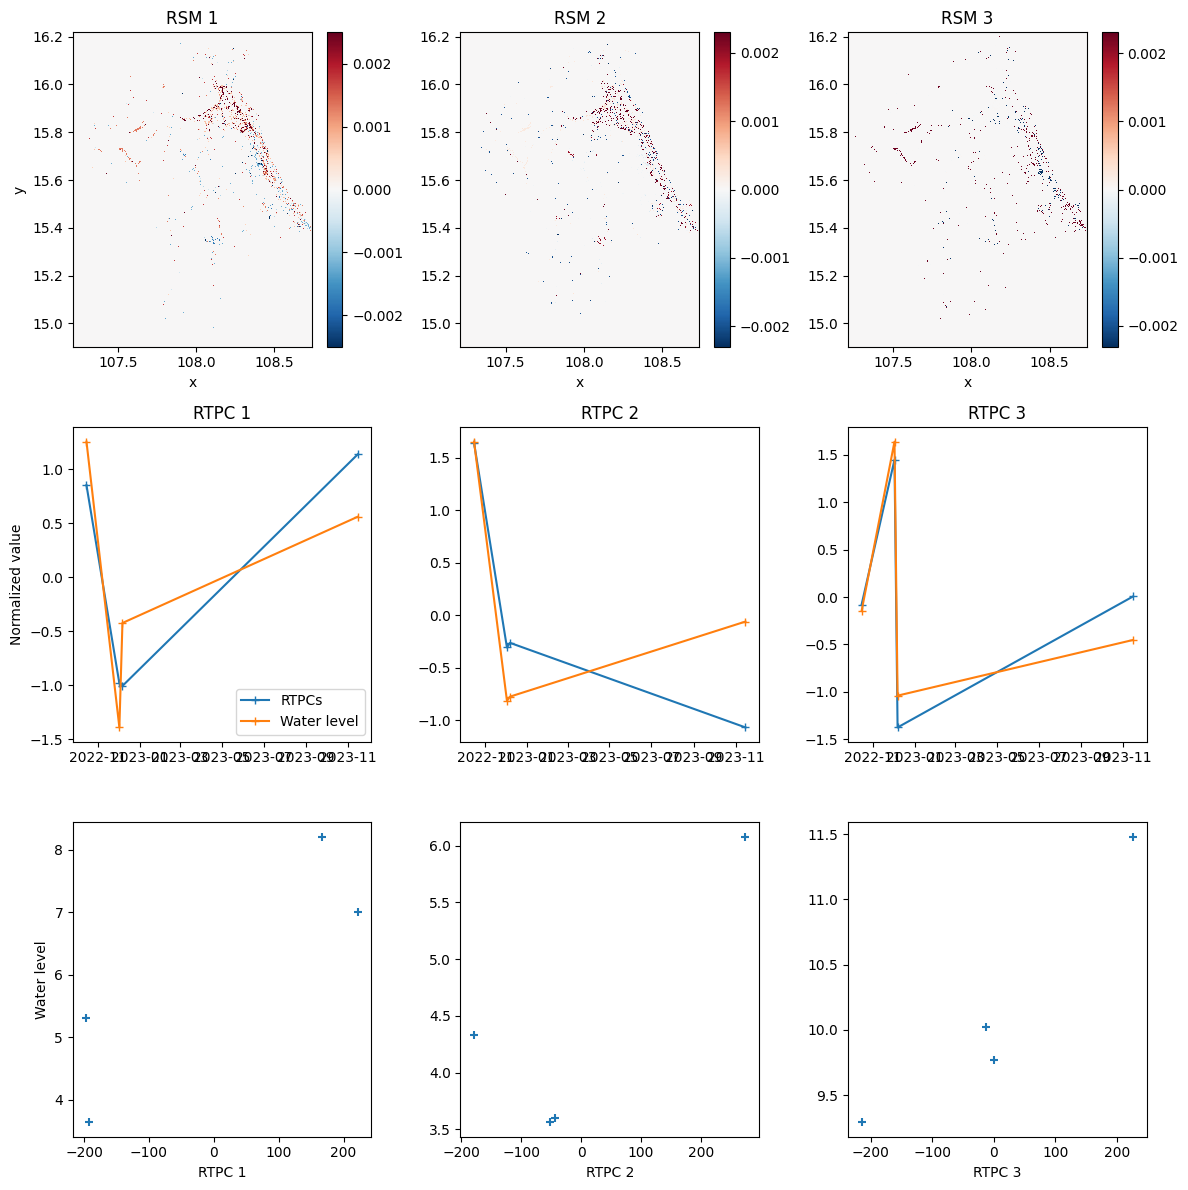

In [120]:
plot_eof_hydro_grid(eof_result, da_water, time_dim="time", site_dim="gaugeid", y_dim="y", x_dim="x")

In [136]:
def combine_eof_hydro(
    ds_eof: xr.Dataset,
    da_hydro: xr.DataArray,
    tpc_hydro_r: xr.Dataset,
    time_dim: str = "time",
    site_dim: str = "site",
    degree: int = 2,
) -> xr.Dataset:
    """
    Combine REOF/EOF results for the water-related modes (output of `find_hydro_mode`)
    with their matched hydrological data, and fit a polynomial relating each mode's
    temporal pattern to its water level.

    args:
        ds_eof: Dataset with EOF or REOF results (output of `reof`)
        da_hydro: DataArray with hydrological data
        tpc_hydro_r: Dataset with the water-related modes (output of `find_hydro_mode`),
            with variables `site` and `best_r`
        time_dim: name of the time dimension/coordinate shared between ds_eof and da_hydro. default = "time"
        site_dim: name of the site/gauge dimension/coordinate in da_hydro. default = "site"
        degree: degree of the polynomial fit relating water level to temporal mode amplitude. default = 2

    returns:
        xr.Dataset: ds_eof subset to the water-related modes, merged with each mode's
        matched hydro series (as `hydro_var`), plus `site`, `best_r`, and per-mode
        polynomial `coefficients`
    """
    mode_dim = "mode"

    eof_sel = ds_eof.sel({mode_dim: tpc_hydro_r[mode_dim].values})

    # match each mode's RTPC timestamps to the closest valid observation at its best-matching gauge
    hydro_sel = xr.concat(
        [
            find_closest_valid_hydro(
                da_hydro.sel({site_dim: [site]}),
                eof_sel[time_dim].values,
                time_dim=time_dim,
                site_dim=site_dim,
            ).sel({site_dim: site})
            for site in tpc_hydro_r.site.values
        ],
        dim=mode_dim,
    )
    hydro_sel = hydro_sel.assign_coords({mode_dim: tpc_hydro_r[mode_dim].values})
    hydro_sel.name = "hydro_var"

    eof_hydro = xr.merge([eof_sel, hydro_sel]).astype(np.float32)
    eof_hydro["site"] = ([mode_dim], tpc_hydro_r.site.values)
    eof_hydro["best_r"] = ([mode_dim], tpc_hydro_r.best_r.values)

    n_sel_modes = eof_hydro.sizes[mode_dim]
    n_coef = degree + 1

    coef_mat = np.zeros([n_sel_modes, n_coef])
    for i in range(n_sel_modes):
        mode_ds = eof_hydro.isel({mode_dim: i})
        q = mode_ds["hydro_var"]
        tpc = mode_ds["temporal_modes"]

        p = np.polynomial.Polynomial.fit(q, tpc, degree)
        coef_mat[i, :] = p.convert().coef

    eof_hydro["degree"] = np.arange(n_coef)
    eof_hydro["coefficients"] = ([mode_dim, "degree"], coef_mat.astype(np.float32))

    return eof_hydro


In [137]:
eof_hydro = combine_eof_hydro(
    eof_result,
    da_water,
    tpc_hydro_r,
    time_dim="time",
    site_dim="gaugeid",
)
eof_hydro


<xarray.Dataset> Size: 443MB
Dimensions:         (mode: 3, y: 4879, x: 5668, time: 4, degree: 3)
Coordinates:
  * mode            (mode) int64 24B 1 2 3
  * y               (y) float64 39kB 16.22 16.22 16.22 16.22 ... 14.9 14.9 14.9
  * x               (x) float64 45kB 107.2 107.2 107.2 ... 108.7 108.7 108.7
  * time            (time) datetime64[ns] 32B 2022-10-15T10:56:00 ... 2023-11...
  * degree          (degree) int64 24B 0 1 2
    gaugeid         (mode) <U3 36B 'ID2' 'ID5' 'ID4'
Data variables:
    spatial_modes   (mode, y, x) float32 332MB -2.917e-13 8.371e-13 ... 0.0 0.0
    temporal_modes  (mode, time) float32 48B 166.1 -191.8 ... -215.1 0.964
    temporal_mean   (y, x) float32 111MB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    explained_var   (mode) float32 12B 0.421 0.3087 0.2703
    hydro_var       (mode, time) float32 48B 8.21 3.64 5.31 ... 11.48 9.29 9.77
    site            (mode) object 24B 'ID2' 'ID5' 'ID4'
    best_r          (mode) float64 24B 0.8748 -0.808 0.9545
    coefficients    (mode, degree) float32 36B -455.2 46.33 ... 1.817e+03 -78.07

In [139]:
eof_hydro["coefficients"].sel(mode=1)

<xarray.DataArray 'coefficients' (degree: 3)> Size: 12B
array([-455.16263  ,   46.33124  ,    4.4358807], dtype=float32)
Coordinates:
  * degree   (degree) int64 24B 0 1 2
    mode     int64 8B 1
    gaugeid  <U3 12B 'ID2'

In [141]:
def plot_regression_fit(eof_hydro: xr.Dataset, mode: int, ax: plt.Axes = None) -> None:
    """
    Plot the fitted polynomial regression between a mode's RTPC and its matched
    water level, together with the underlying data points (output of `combine_eof_hydro`).

    args:
        eof_hydro: Dataset produced by `combine_eof_hydro`, with `hydro_var`,
            `temporal_modes`, `coefficients`, `site` and `best_r` variables
        mode: mode number to plot (matches the `mode` coordinate label)
        ax: existing matplotlib axes to plot on. default = None (creates a new figure)
    """
    mode_ds = eof_hydro.sel(mode=mode)
    q = mode_ds["hydro_var"].values
    tpc = mode_ds["temporal_modes"].values
    coef = mode_ds["coefficients"].values
    site = mode_ds["site"].values.item()
    best_r = mode_ds["best_r"].values.item()

    poly = np.polynomial.Polynomial(coef)
    q_fit = np.linspace(np.nanmin(q), np.nanmax(q), 200)
    tpc_fit = poly(q_fit)

    created_fig = ax is None
    if created_fig:
        _, ax = plt.subplots(figsize=(5, 5))

    ax.scatter(q, tpc, marker="+", label="Observed")
    ax.plot(q_fit, tpc_fit, color="black", label="Polynomial fit")
    ax.set_xlabel(f"Water level ({site})")
    ax.set_ylabel(f"RTPC {mode}")
    ax.set_title(f"RTPC {mode} vs. water level (r={best_r:.2f})")
    ax.legend()

    if created_fig:
        plt.show()


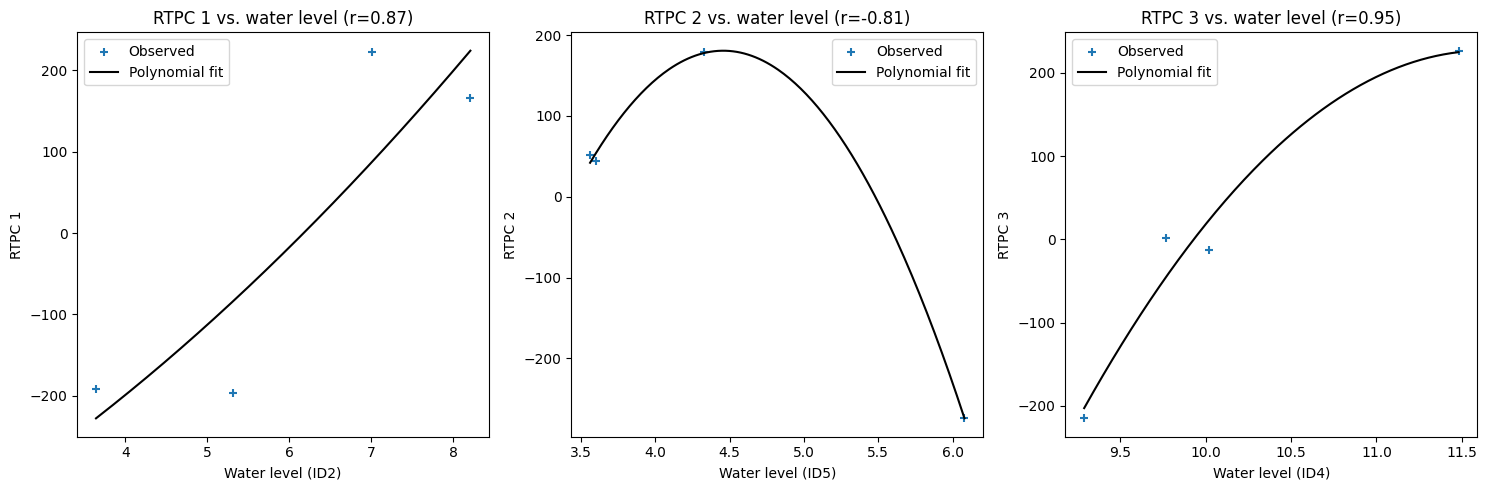

In [142]:
n_modes = eof_hydro.sizes["mode"]
fig, axes = plt.subplots(1, n_modes, figsize=(5 * n_modes, 5), squeeze=False)

for i, mode in enumerate(eof_hydro["mode"].values):
    plot_regression_fit(eof_hydro, mode, ax=axes[0, i])

plt.tight_layout()
plt.show()
